# 05 · 二维 FNO 解椭圆 PDE（高级）

**前置：** 03–04；二维 FFT。**目标：** 处理二维函数场、正确保留正负频率块、展示跨网格预测。

在二维周期单位方形上解 $-\Delta u+u=f$。这是带反应项的 Poisson 方程（screened Poisson）。$+u$ 使零模也可逆，不必额外固定均值。它不是可变系数 Darcy 方程；用此例先隔离二维架构的难点。

频谱解为 $\widehat u_{k,l}=\widehat f_{k,l}/[1+(2\pi k)^2+(2\pi l)^2]$。训练用 $v=Su$，$S=1+4\pi^2$，用于改善数值尺度。

## 原理详解 A：反应 Poisson 的频谱解与唯一性

二维周期 Fourier 基为 $e^{i2\pi(kx+ly)}$，Laplace 作用为
$$
-\Delta e^{i2\pi(kx+ly)}=4\pi^2(k^2+l^2)e^{i2\pi(kx+ly)}.
$$
因此
$$
\widehat u_{k,l}=\frac{\widehat f_{k,l}}{1+4\pi^2(k^2+l^2)}.
$$
零模式分母为 1，所以 forcing 的均值决定解的均值。若去掉反应项，只剩 $-\Delta u=f$，零模方程要求 $\widehat f_{0,0}=0$，而解还可以加任意常数，必须再固定均值。

唯一性也可以不依赖 Fourier 推导。若两解之差为 w，则满足 $-\Delta w+w=0$。乘 w 并周期分部积分：
$$
\int_\Omega(|\nabla w|^2+|w|^2)\,d\boldsymbol x=0.
$$
故 w 必为零。对于给定 f，物理解是唯一的，残差为零不会留下常数自由度。

输出缩放 $v=Su$ 后，方程变成 $-\Delta v+v=Sf$，因此如果将来增加物理损失，右端也要乘 S。只缩放输出而保留原右端，会使物理损失要求一个错误的方程。

## 原理详解 B：二维频率布局与通道运算

rFFT2 对最后一轴压缩，所以
$$
[B,C,N_x,N_y]\longrightarrow[B,C,N_x,\lfloor N_y/2\rfloor+1].
$$
第一轴仍按 FFT 顺序排列：零频和正频在开头，负频在末尾。于是保留的两个角块分别覆盖低 $+k_x$ 与低 $-k_x$，最后一轴保留非负 $k_y$。

代码的 $R_{i,o,k,l}$ 对每个二维频率进行通道混合：
$$
\widehat w_o(k,l)=\sum_iR_{i,o,k,l}\widehat v_i(k,l).
$$
einsum 中 b 是批次，i/o 是输入/输出通道，x/y 在该表达式中是频率索引，并不是物理坐标。把这些轴混淆，网络可能仍有合法 shape，却执行了错误的数学运算。

实二维信号的共轭对称关联是
$$
\widehat v(-k,-l)=\overline{\widehat v(k,l)},
$$
不是单独翻转某一轴即可恢复全部频谱。压缩最后一轴以后，第一轴的正负频率仍需要表示。两组权重学习后，iRFFT2 负责返回实数场，特别频率线的约束也由实逆变换处理。

本章有效 modes 被限制到不超过第一轴一半，防止顶部与底部角块重叠。空间坐标四个 sin/cos 通道给出周期位置特征，lifting 将 5 个输入通道映射到 width 个潜在通道。

## 原理详解 C：复杂度、坐标尺度与二维误差

记总网格数为 $M=N_xN_y$、宽度为 C。FFT 部分的数量级约为 $O(CM\log M)$；两个频率块的通道混合约为 $O(C^2m^2)$，点态通道混合约为 $O(C^2M)$。这些估计省略常数、batch 和具体库实现，但能说明增加 width 与增加网格会增加不同部分的成本。

若物理区域变为 $[0,L_x)\times[0,L_y)$，真实谱符号应为
$$
1+\left(\frac{2\pi k}{L_x}\right)^2+
\left(\frac{2\pi l}{L_y}\right)^2.
$$
本章 helper 假设两个长度都为 1。修改显示图的 extent 不会自动修改 PDE 或数值波数。

体积或面积误差必须在全部网格点上算。二维图采用共同色标，是为了避免每幅图独立拉伸颜色后把幅度误差掩盖。带符号误差图可以显示相位偏差、局部偏差和对称结构，而相对范数汇总整体大小。

最后要区分本章与变系数问题：
$$
-\nabla\cdot(a\nabla u)=-a\Delta u-\nabla a\cdot\nabla u.
$$
a 随空间变化时产生模式耦合，不能直接套用常系数分母逐频率相除；09 章会改用守恒离散与线性迭代求解器。

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "tutorial_utils.py").exists():
    ROOT = ROOT / "neural_operator_tutorials"
if not (ROOT / "tutorial_utils.py").exists():
    raise FileNotFoundError("Please start Jupyter in PINO or neural_operator_tutorials")
sys.path.insert(0, str(ROOT))
import torch
get_ipython().run_line_magic('matplotlib', 'inline')
from tutorial_utils import *
seed_all()
print("device:", DEVICE, "| smoke:", SMOKE)


device: cpu | smoke: False


## 1. 二维数据与解析频谱参考解

同一组系数可以在不同网格上采样。二维周期网格两轴都不重复端点。forcing 只含少数平滑频率，是入门数据分布；网络在这个分布上的表现不能代表复杂 Darcy 场。

In [2]:
SCALE = 1+4*torch.pi**2
pairs = [(1,0),(0,1),(1,1),(2,1),(1,2),(2,2)]
def forcing2d(coeff,n):
    x = torch.arange(n)/n
    X,Y = torch.meshgrid(x,x,indexing="ij")
    basis = []
    for k,l in pairs:
        angle = 2*torch.pi*(k*X+l*Y)
        basis.extend([angle.sin()/(k*k+l*l),angle.cos()/(k*k+l*l)])
    return torch.einsum("bp,pij->bij",coeff,torch.stack(basis))
def solve2d(f):
    n = f.shape[-1]
    kx = 2*torch.pi*torch.fft.fftfreq(n,d=1/n)
    ky = 2*torch.pi*torch.fft.rfftfreq(n,d=1/n)
    denominator = 1+kx[:,None].square()+ky[None,:].square()
    return torch.fft.irfft2(torch.fft.rfft2(f)/denominator,s=(n,n))
ntrain,ntest = counts(192,48)
atrain,aval,atest = torch.randn(ntrain,12),torch.randn(ntest,12),torch.randn(ntest,12)
ftrain,fval,ftest = [forcing2d(a,24) for a in [atrain,aval,atest]]
vtrain,vval,vtest = [SCALE*solve2d(f) for f in [ftrain,fval,ftest]]
print("batch,x,y:",ftrain.shape)
# Manufactured single mode: -Delta sin(2pi*x)+sin(2pi*x)=SCALE*sin(2pi*x).
grid = torch.arange(24)/24
single = (2*torch.pi*grid).sin()[None,:,None].expand(1,24,24)
assert (solve2d(SCALE*single)-single).abs().max()<1e-5

batch,x,y: torch.Size([192, 24, 24])


## 2. rFFT2 的频率布局

输入 $[B,C,N_x,N_y]$，输出 $[B,C,N_x,N_y/2+1]$。仅最后一轴因共轭对称而缩短；第一轴仍含正、负频率。因此低频块位于第一轴的顶部和底部，需要两组可学习权重。

epoch    1 | train MSE 1.912e+00 | val relative L2 0.952


epoch   20 | train MSE 3.162e-04 | val relative L2 0.015


epoch   40 | train MSE 1.297e-04 | val relative L2 0.010


epoch   60 | train MSE 8.587e-05 | val relative L2 0.009


epoch   80 | train MSE 4.645e-05 | val relative L2 0.006


epoch  100 | train MSE 3.511e-05 | val relative L2 0.006


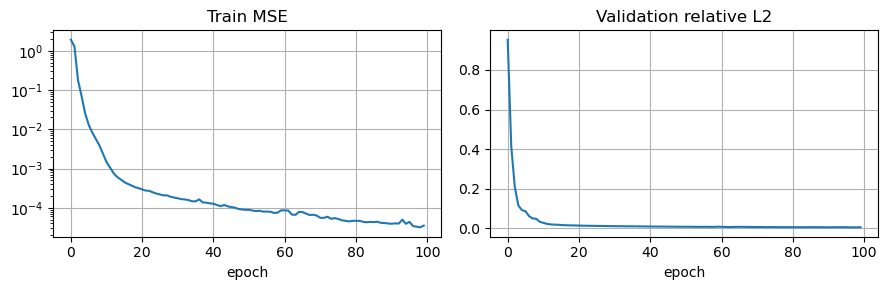

Test relative L2: mean=0.0060, median=0.0052, max=0.0154


In [3]:
class SpectralConv2d(nn.Module):
    def __init__(self,width,modes=5):
        super().__init__()
        self.modes = modes
        self.positive = nn.Parameter(torch.randn(width,width,modes,modes,dtype=torch.cfloat)/width)
        self.negative = nn.Parameter(torch.randn(width,width,modes,modes,dtype=torch.cfloat)/width)
    def forward(self,v):
        nx,ny = v.shape[-2:]
        vf = torch.fft.rfft2(v)
        m = min(self.modes,nx//2,ny//2+1)
        out = torch.zeros_like(vf)
        out[:,:,:m,:m] = torch.einsum("bixy,ioxy->boxy",vf[:,:,:m,:m],self.positive[:,:,:m,:m])
        out[:,:,-m:,:m] = torch.einsum("bixy,ioxy->boxy",vf[:,:,-m:,:m],self.negative[:,:,:m,:m])
        return torch.fft.irfft2(out,s=(nx,ny))

class FNO2d(nn.Module):
    def __init__(self,width=16,modes=5):
        super().__init__()
        self.lift = nn.Conv2d(5,width,1)
        self.spectral = nn.ModuleList([SpectralConv2d(width,modes) for _ in range(3)])
        self.local = nn.ModuleList([nn.Conv2d(width,width,1) for _ in range(3)])
        self.project = nn.Sequential(nn.Conv2d(width,32,1),nn.GELU(),nn.Conv2d(32,1,1))
    def forward(self,f):
        n = f.shape[-1]
        x = torch.arange(n,device=f.device,dtype=f.dtype)/n
        X,Y = torch.meshgrid(x,x,indexing="ij")
        pos = torch.stack([(2*torch.pi*X).sin(),(2*torch.pi*X).cos(),
                           (2*torch.pi*Y).sin(),(2*torch.pi*Y).cos()])
        inp = torch.cat([f[:,None],pos[None].expand(len(f),-1,-1,-1)],dim=1)
        v = self.lift(inp)
        for spectral,local in zip(self.spectral,self.local):
            v = torch.nn.functional.gelu(spectral(v)+local(v))
        return self.project(v).squeeze(1)

model = FNO2d()
history = fit(model,ftrain,vtrain,fval,vval,steps=epochs(100),batch=16)
plot_history(history)
pred,error = report(model,ftest,vtest)

## 3. 二维图与误差色标

参考解和预测使用同一个色标，误差使用对称色标，避免自动缩放掩盖差别。imshow 的坐标对应周期离散点，图像边缘不是额外的物理边界。

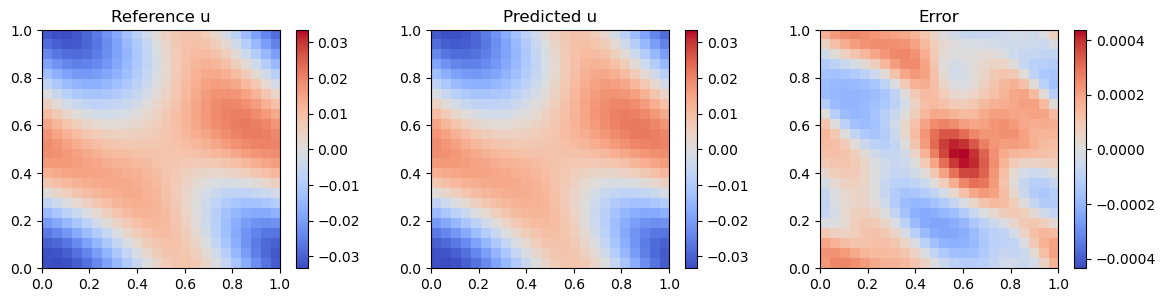

Test relative L2: mean=0.0060, median=0.0052, max=0.0154


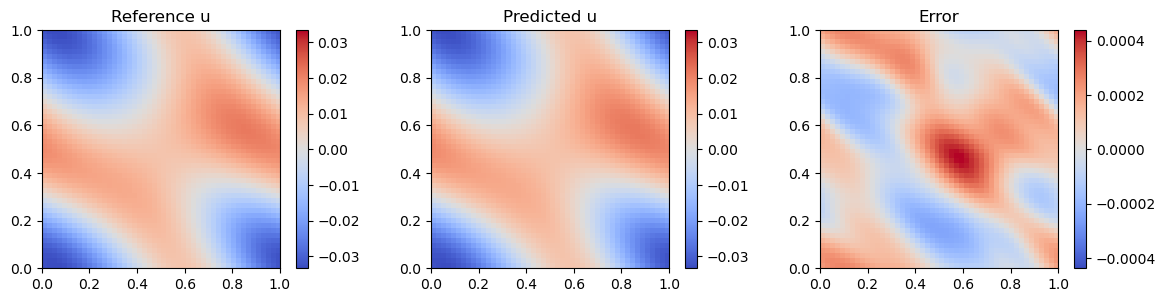

24x24: 0.0060351029969751835 48x48: 0.006035274360328913


In [4]:
def show_fields(truth,pred,index=0):
    truth,pred = truth[index]/SCALE,pred[index]/SCALE
    difference = pred-truth
    vmax = max(truth.abs().max().item(),pred.abs().max().item(),1e-8)
    emax = max(difference.abs().max().item(),1e-8)
    fig,ax = plt.subplots(1,3,figsize=(12,3))
    for a,z,title,limit in zip(ax,[truth,pred,difference],
                              ["Reference u","Predicted u","Error"],[vmax,vmax,emax]):
        im = a.imshow(z.numpy(),origin="lower",extent=[0,1,0,1],
                      cmap="coolwarm",vmin=-limit,vmax=limit)
        a.set_title(title); a.grid(False); fig.colorbar(im,ax=a)
    plt.tight_layout(); plt.show()
show_fields(vtest,pred)
finef = forcing2d(atest,48)
finev = SCALE*solve2d(finef)
finepred,fineerror = report(model,finef,finev)
show_fields(finev,finepred)
print("24x24:",error.mean().item(),"48x48:",fineerror.mean().item())

**练习：** ① 去掉负频率块，比较误差；② 给 forcing 加入非零均值，检查反应项如何处理零模；③ 增加频带并相应增大 modes；④ 若改为 Dirichlet 边界，解释为何不能直接沿用周期频谱参考解。

想继续研究 Darcy 方程，需要另写 $-\nabla\cdot(a\nabla u)=f$ 的可靠求解器，让系数场 $a(x,y)$ 成为输入，并重新设计边界处理。